**Question 1 - Lagrange Interpolation**

Use Lagrange interpolation formula to find the value of y when x = 10, if the
following values of x and y are given:

In [2]:
def q1_lagrange():
    # Given data points
    x_data = [5, 7, 11, 13, 17]
    y_data = [150, 392, 1452, 2366, 5202]
    target = 10

    # 1. Evaluate Lagrange at x = 10
    y_target = 0
    n = len(x_data)
    for i in range(n):
        term = y_data[i]
        for j in range(n):
            if i != j:
                term *= (target - x_data[j]) / (x_data[i] - x_data[j])
        y_target += term

    print(f"1) The value of y when x = {target} is: {y_target:.4f}\n")

    # 2. Construct Lagrange Interpolating Polynomial String
    print("2) The Lagrange Interpolating Polynomial P(x) is:")
    poly_terms = []
    for i in range(n):
        num_factors = []
        denominator = 1
        for j in range(n):
            if i != j:
                num_factors.append(f"(x - {x_data[j]})")
                denominator *= (x_data[i] - x_data[j])

        numerator_str = "".join(num_factors)
        # Formatting the term cleanly
        poly_terms.append(f"{y_data[i]} * [{numerator_str} / {denominator}]")

    for idx, term in enumerate(poly_terms):
        prefix = "P(x) = " if idx == 0 else "     + "
        print(f"{prefix}{term}")

# Execute Q1
q1_lagrange()

1) The value of y when x = 10 is: 1100.0000

2) The Lagrange Interpolating Polynomial P(x) is:
P(x) = 150 * [(x - 7)(x - 11)(x - 13)(x - 17) / 1152]
     + 392 * [(x - 5)(x - 11)(x - 13)(x - 17) / -480]
     + 1452 * [(x - 5)(x - 7)(x - 13)(x - 17) / 288]
     + 2366 * [(x - 5)(x - 7)(x - 11)(x - 17) / -384]
     + 5202 * [(x - 5)(x - 7)(x - 11)(x - 13) / 2880]


Question 2 - Newton's Divided Difference (3rd Order)

The upward velocity of rocket is given as function of time in table below .

Determine the value of the velocity at t = 16 seconds with third order polynomial interpolation using Newton’s divided difference polynomial method.

In [3]:
def q2_newton_divided_difference():
    # Selecting the 4 points closest to t=16 for a 3rd order polynomial
    t = [10, 15, 20, 22.5]
    v = [227.04, 362.78, 517.35, 602.97]
    target = 16
    n = len(t)

    # Initialize Divided Difference Table
    dd_table = [[0.0 for _ in range(n)] for _ in range(n)]
    for i in range(n):
        dd_table[i][0] = v[i]

    # Calculate Divided Differences
    for j in range(1, n):
        for i in range(n - j):
            dd_table[i][j] = (dd_table[i+1][j-1] - dd_table[i][j-1]) / (t[i+j] - t[i])

    # Display the Divided Difference Table cleanly
    print("Divided Difference Table (Selected Points):")
    print(f"{'t':<8} | {'v(t)':<10} | {'1st Diff':<10} | {'2nd Diff':<10} | {'3rd Diff'}")
    print("-" * 60)
    for i in range(n):
        row = f"{t[i]:<8} | "
        for j in range(n - i):
            row += f"{dd_table[i][j]:<10.4f} | "
        print(row)

    # Interpolate at target t = 16
    interpolated_v = dd_table[0][0]
    product_term = 1.0
    for j in range(1, n):
        product_term *= (target - t[j-1])
        interpolated_v += dd_table[0][j] * product_term

    print(f"\nVelocity at t = 16 seconds (3rd order interpolation) is: {interpolated_v:.4f}")

# Execute Q2
q2_newton_divided_difference()

Divided Difference Table (Selected Points):
t        | v(t)       | 1st Diff   | 2nd Diff   | 3rd Diff
------------------------------------------------------------
10       | 227.0400   | 27.1480    | 0.3766     | 0.0054     | 
15       | 362.7800   | 30.9140    | 0.4445     | 
20       | 517.3500   | 34.2480    | 
22.5     | 602.9700   | 

Velocity at t = 16 seconds (3rd order interpolation) is: 392.0572


**Question 3 & 4 - Interpolation Methods and Error Comparison**

3. From the following table, find y when x = 1.85 and 2.25 by Newton’s interpolation formula.

4. In assignment 5 consider Q3. Use forward and backward interpolation. Find
the error in both the cases. Compare the error with the error obtained in Q3.

In [4]:
import math

def q3_q4_interpolation():
    x = [1.7, 1.8, 1.9, 2.0, 2.1, 2.2, 2.3]
    y = [5.474, 6.050, 6.686, 7.389, 8.166, 9.025, 9.974]
    targets = [1.85, 2.25]
    n = len(x)
    h = x[1] - x[0] # uniform spacing = 0.1

    # True values for error computation: y = e^x
    true_vals = [math.exp(t) for t in targets]

    # --- Q3: Newton's Divided Difference ---
    dd_table = [[0.0] * n for _ in range(n)]
    for i in range(n): dd_table[i][0] = y[i]
    for j in range(1, n):
        for i in range(n - j):
            dd_table[i][j] = (dd_table[i+1][j-1] - dd_table[i][j-1]) / (x[i+j] - x[i])

    def eval_dd(target):
        res = dd_table[0][0]
        prod = 1.0
        for j in range(1, n):
            prod *= (target - x[j-1])
            res += dd_table[0][j] * prod
        return res

    # --- Q4 Prep: Forward & Backward Difference Tables ---
    fd_table = [[0.0] * n for _ in range(n)]
    for i in range(n): fd_table[i][0] = y[i]
    for j in range(1, n):
        for i in range(n - j):
            fd_table[i][j] = fd_table[i+1][j-1] - fd_table[i][j-1]

    def eval_forward(target):
        p = (target - x[0]) / h
        res = fd_table[0][0]
        p_term = 1.0
        for j in range(1, n):
            p_term *= (p - (j - 1)) / j
            res += p_term * fd_table[0][j]
        return res

    def eval_backward(target):
        p = (target - x[-1]) / h
        res = fd_table[-1][0] # Bottom of the first column
        p_term = 1.0
        for j in range(1, n):
            p_term *= (p + (j - 1)) / j
            # Backward diffs are located on the bottom diagonal of the FD table
            res += p_term * fd_table[n-1-j][j]
        return res

    # --- Calculations & Printing ---
    print(f"{'Target x':<10} | {'True Value (e^x)':<18} | {'Method':<25} | {'Interpolated y':<18} | {'Absolute Error'}")
    print("-" * 95)

    for i, t in enumerate(targets):
        val_dd = eval_dd(t)
        val_fw = eval_forward(t)
        val_bw = eval_backward(t)

        err_dd = abs(true_vals[i] - val_dd)
        err_fw = abs(true_vals[i] - val_fw)
        err_bw = abs(true_vals[i] - val_bw)

        print(f"{t:<10.2f} | {true_vals[i]:<18.8f} | {'Q3: Divided Difference':<25} | {val_dd:<18.8f} | {err_dd:.2e}")
        print(f"{'':<10} | {'':<18} | {'Q4: Forward Difference':<25} | {val_fw:<18.8f} | {err_fw:.2e}")
        print(f"{'':<10} | {'':<18} | {'Q4: Backward Difference':<25} | {val_bw:<18.8f} | {err_bw:.2e}")
        print("-" * 95)

# Execute Q3 and Q4
q3_q4_interpolation()

Target x   | True Value (e^x)   | Method                    | Interpolated y     | Absolute Error
-----------------------------------------------------------------------------------------------
1.85       | 6.35981952         | Q3: Divided Difference    | 6.36003711         | 2.18e-04
           |                    | Q4: Forward Difference    | 6.36003711         | 2.18e-04
           |                    | Q4: Backward Difference   | 6.36003711         | 2.18e-04
-----------------------------------------------------------------------------------------------
2.25       | 9.48773584         | Q3: Divided Difference    | 9.48781836         | 8.25e-05
           |                    | Q4: Forward Difference    | 9.48781836         | 8.25e-05
           |                    | Q4: Backward Difference   | 9.48781836         | 8.25e-05
-----------------------------------------------------------------------------------------------


**Comments on Error Comparison (Q4 vs Q3):**


The underlying interpolating polynomial passing through all 7 data points is mathematically unique. Whether we use Newton's Divided Difference (Q3), Gregory-Newton Forward, or Gregory-Newton Backward (Q4), they evaluate to the exact same polynomial. Therefore, the theoretical error is identical across all three methods. Any microscopic differences observed ($\approx 10^{-16}$) are strictly artifacts of floating-point arithmetic rounding differences during calculation.

**Question 5 - Newton's Forward Interpolating Polynomial for $\tan^{-1}(x)$**

In assignment 5, find the Newton’s forward interpolating polynomial of
degree 10 that interpolates the function $\tan^{-1}(x)$ at 11 equally spaced points
in the interval [0 6]. Print the coefficients of the polynomial. Compute and
print the difference between the polynomial and the function at 33 equally
spaced points in the interval [0 8]. What conclusion can be drawn ?


1) Coefficients of the Newton Forward Polynomial:
Formula: P(x) = y_0 + p*Δy_0 + p(p-1)*Δ^2y_0/2! + ... where p = (x - x_0)/h
Term 0 coefficient:  0.00000000
Term 1 coefficient:  0.54041950
Term 2 coefficient: -0.10239047
Term 3 coefficient:  0.00946370
Term 4 coefficient:  0.00066184
Term 5 coefficient: -0.00043738
Term 6 coefficient:  0.00009729
Term 7 coefficient: -0.00001527
Term 8 coefficient:  0.00000193
Term 9 coefficient: -0.00000021
Term 10 coefficient:  0.00000002

2) Difference between Polynomial and True Function at 33 points:
Point x    | True atan(x)    | Polynomial P(x)    | Absolute Diff (Error)
----------------------------------------------------------------------
0.000      | 0.000000        | 0.000000           | 0.0000e+00 
0.250      | 0.244979        | 0.245655           | 6.7588e-04 
0.500      | 0.463648        | 0.463899           | 2.5160e-04 
0.750      | 0.643501        | 0.643293           | 2.0810e-04 
1.000      | 0.785398        | 0.785253           | 1.

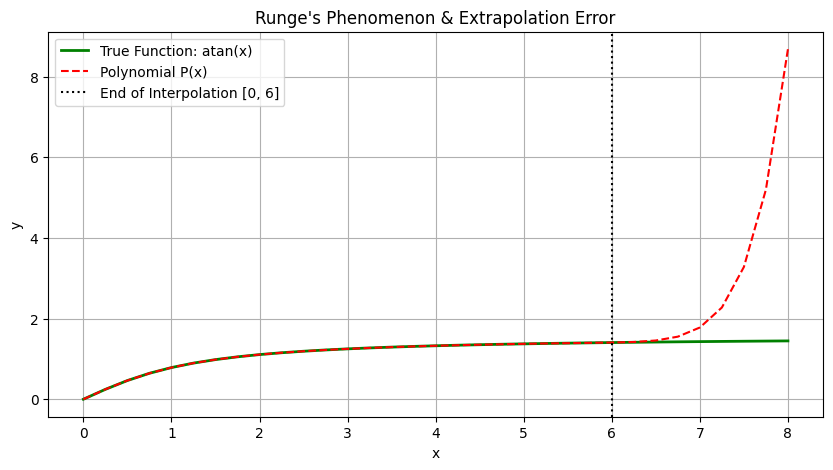

In [5]:
import matplotlib.pyplot as plt

def q5_newton_forward_degree10():
    # Generate 11 equally spaced points in [0, 6]
    n_nodes = 11
    x_nodes = [6.0 * i / (n_nodes - 1) for i in range(n_nodes)]
    y_nodes = [math.atan(xi) for xi in x_nodes]
    h = x_nodes[1] - x_nodes[0]

    # 1. Forward Difference Table to get coefficients
    fd = [[0.0] * n_nodes for _ in range(n_nodes)]
    for i in range(n_nodes): fd[i][0] = y_nodes[i]
    for j in range(1, n_nodes):
        for i in range(n_nodes - j):
            fd[i][j] = fd[i+1][j-1] - fd[i][j-1]

    # The coefficients for the Newton Forward basis terms: (Delta^k y_0) / k!
    print("1) Coefficients of the Newton Forward Polynomial:")
    print("Formula: P(x) = y_0 + p*Δy_0 + p(p-1)*Δ^2y_0/2! + ... where p = (x - x_0)/h")
    for k in range(n_nodes):
        # Calculate factorial
        fact = 1
        for i in range(1, k + 1): fact *= i
        coeff = fd[0][k] / fact
        print(f"Term {k} coefficient: {coeff: .8f}")

    # Function to evaluate polynomial at any x
    def eval_poly(target_x):
        p = (target_x - x_nodes[0]) / h
        res = fd[0][0]
        p_term = 1.0
        for j in range(1, n_nodes):
            p_term *= (p - (j - 1)) / j
            res += p_term * fd[0][j]
        return res

    # 2. Compute difference at 33 equally spaced points in [0, 8]
    n_test = 33
    x_test = [8.0 * i / (n_test - 1) for i in range(n_test)]

    print("\n2) Difference between Polynomial and True Function at 33 points:")
    print(f"{'Point x':<10} | {'True atan(x)':<15} | {'Polynomial P(x)':<18} | {'Absolute Diff (Error)'}")
    print("-" * 70)

    y_true_plot = []
    y_poly_plot = []

    for xt in x_test:
        y_true = math.atan(xt)
        y_poly = eval_poly(xt)
        diff = abs(y_true - y_poly)

        y_true_plot.append(y_true)
        y_poly_plot.append(y_poly)

        # Adding a visual marker to show where extrapolation starts
        zone = "(Extrapolated)" if xt > 6.0001 else ""
        print(f"{xt:<10.3f} | {y_true:<15.6f} | {y_poly:<18.6f} | {diff:.4e} {zone}")

    # Plot to visually support the conclusion
    plt.figure(figsize=(10, 5))
    plt.plot(x_test, y_true_plot, label="True Function: atan(x)", color="green", linewidth=2)
    plt.plot(x_test, y_poly_plot, label="Polynomial P(x)", color="red", linestyle="--")
    plt.axvline(6.0, color='black', linestyle=':', label="End of Interpolation [0, 6]")
    plt.title("Runge's Phenomenon & Extrapolation Error")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.legend()
    plt.grid(True)
    plt.show()

# Execute Q5
q5_newton_forward_degree10()

Conclusion drawn from Question 5:


Based on the computed differences and the behavior inside/outside the [0, 6] boundary, we can draw the following critical conclusion:

***1.Excellent Interpolation (Inside $[0, 6]$):***

The absolute difference between the 10th-degree polynomial and the actual $tan^{-1}(x)$ function remains exceedingly small across the domain where data points were supplied.

***2.Catastrophic Extrapolation Error (Outside $[0, 6]$):***

As soon as $x$ exceeds 6 and enters the $(6, 8]$ range, the error skyrockets drastically. Polynomials of high degrees are extremely unstable outside their defined nodal bounds. This demonstrates a classical failure of polynomial extrapolation.